In [1]:
# import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [3]:
#1. import database/data

In [4]:
# connect database to sql
# this is function in sqlite3 for connection
conn=sqlite3.connect('customer_churn.db')

sql_query="""
        SELECT name
        FROM sqlite_master
        WHERE type='table'
"""

tables=pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * FROM {table_name}",conn)
    globals()[f"df_{table_name}"]=df
    print(f"Created dataframe: df_{table_name}")

conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [5]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# Close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [6]:
# head means showing top rows is used to give general idea of row and column
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [7]:
# data cleaning

# info shows number of column, rows, nullvalue
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [8]:
# it show last value
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [9]:
# a.  rename column -name 
# b. drop column -interest and pincode --because it is useless
# c. change datatype
# d. data standardization -gender
# e. fix missing value -country

In [10]:
# a. rename col -name

# shift+tab -- use to show which value rename
# inplace is used to permanently change name
df_db_customer.rename(columns = {'name':'customer_name'},inplace=True)
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [11]:
print(df_db_customer.columns.tolist())

['customerid', 'customer_name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']


In [12]:
# b. drop column -interest and pinco

df_db_customer.drop(columns=['interests','pincode'],inplace=True,errors='ignore')
print(df_db_customer.columns.tolist())

['customerid', 'customer_name', 'country', 'state', 'gender', 'dob']


In [13]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     21 non-null     str  
 1   customer_name  21 non-null     str  
 2   country        18 non-null     str  
 3   state          21 non-null     str  
 4   gender         21 non-null     str  
 5   dob            21 non-null     str  
dtypes: str(6)
memory usage: 1.1 KB


In [14]:
# c. change datatype -dob

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])
df_db_customer['dob']

0    1982-04-12
1    1995-11-23
2    1978-02-15
3    2001-08-30
4    1990-05-05
5    1988-12-10
6    1976-09-21
7    1999-03-14
8    1985-07-07
9    1993-10-29
10   1997-01-22
11   1981-06-18
12   2004-12-01
13   1992-04-25
14   1979-11-11
15   1986-02-28
16   1994-08-19
17   2000-09-02
18   1983-12-30
19   1991-05-14
20   1977-10-06
Name: dob, dtype: datetime64[us]

In [15]:
# d. data standardization -gender
#df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male','Women' : 'Female'})

In [16]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [17]:
# e. fix missing value -country

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [18]:
# fill is use to fill valuedf_db_customer['country'].fillna('na')

In [19]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,NaN,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,NaN,Kathmandu
9,Nepal,Kathmandu


In [20]:
# country and state -unique value pair

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [21]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [22]:
# for checking
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,India,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,Nepal,Kathmandu
9,Nepal,Kathmandu


In [23]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [24]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [25]:
date_col=['subscription_start_date','renewal_date','cancellation_date']

df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [26]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [27]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [28]:
df_db_support.drop(columns=['col_1','comment'],inplace=True)

In [29]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [30]:
# 3- feaure engineering and data analysis

In [31]:
# create a new column using existing column -churn flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [32]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [33]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
 11  churn_flag               21 non-null     int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 2.1 KB


In [34]:
# join the table subscription customer and support

# first fix support table duplicates then merge
df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid',how='left')
    .merge(df_db_support, on = 'customerid',how='left'))

In [35]:
df.shape

(23, 20)

In [36]:
df_db_subscription.shape

(21, 12)

In [57]:
# 21 row ahe tr mg join nantr 23 kashe ale duplicate asel

In [37]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN


In [38]:
# yatun unique mhiti padel


df_db_subscription['customerid'].nunique()

21

In [39]:
df_db_customer['customerid'].nunique()

21

In [40]:
df_db_support['customerid'].nunique()       # unique 7 ahe

7

In [41]:
df_db_support['customerid'].size           # pn size 9 dakhvt ahe yatle 2 mule jasta dakhvt ahe

9

In [42]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30


In [43]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [44]:
# fix this then join

# complaint_count navach navin column banla
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')


In [45]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
7,0022-TCJCI,2024-09-13,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2


In [46]:
# latest record chya value thevach ahe baki delete

df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep = 'last')

In [47]:
df_db_support['customerid'].size

7

In [48]:
# merge dataframe
df = (df_db_subscription
    .merge(df_db_customer, on = 'customerid',how='left')
    .merge(df_db_support, on = 'customerid',how='left'))

In [49]:
df.shape

(21, 21)

In [50]:
# sgla data ek excel file madhe gheun yeu tyni smjala easy hoil
# he aplya file madhe gela
df.to_csv('exported_churn_data_me.csv',index=False)

In [81]:
# DATA ANALYSIS

In [84]:
# 1- churn rate

In [51]:
# to see column

df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [52]:
# it show churn rate variable madhe store kru ani proper print

churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ",round(churn_rate,2),"%")

Churn Rate =  28.57 %


In [53]:
# 2- RETENTION RATE
# opposite as churn rate 
# churn rate mhnje kiti rate ni shodun gele
# 28.57% user gele sodun ani 71.43% ahe still

retention_rate = 100 - churn_rate
print("Retention Rate = ",round(retention_rate,2),"%")

Retention Rate =  71.43 %


In [54]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0


In [98]:
#3- churn by plan type

churn_by_plan = (df.groupby ('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_per'))
print(churn_by_plan)

  plan_type  churn_rate_per
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [101]:
#4 a. churn by state - sum(revenue) and count of users
#4 b. churn by subscription type - sum(revenue) and count of users

In [55]:
#4 a- churn by state

churn_by_state = df.groupby('state').agg(churn_rate=('churn_flag','mean'),
sum_revenue=('monthly_charges','sum'),
count_users=('customerid','nunique')).reset_index()

churn_by_state['churn_rate']=(churn_by_state['churn_rate']*100).round(2)
print(churn_by_state)



           state  churn_rate  sum_revenue  count_users
0          Delhi       25.00        52.96            4
1      Karnataka      100.00        20.98            2
2      Kathmandu        0.00        20.98            2
3    Maharashtra        0.00        50.97            3
4      Meghalaya       66.67        42.97            3
5       Nagaland        0.00        22.99            1
6      Rajasthan        0.00        36.98            2
7      Telangana       50.00        30.98            2
8  Uttar Pradesh        0.00       115.98            2


In [56]:
#4-b churn by subscription_type

churn_by_subscription_type = df.groupby('subscription_type').agg(churn_rate=('churn_flag','mean'),
sum_revenue=('monthly_charges','sum'),
count_users=('customerid','nunique')).reset_index()

churn_by_subscription_type['churn_rate']=(churn_by_subscription_type['churn_rate']*100).round(2)
print(churn_by_subscription_type)

  subscription_type  churn_rate  sum_revenue  count_users
0           Organic        0.00       145.91            9
1              Paid       16.67       174.94            6
2          Refferal       83.33        74.94            6


In [111]:
#5- ARPU -[AVERAGE REVENUE PER USER]

In [57]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [58]:
arpu = df['monthly_charges'].mean()
print('ARPU =',round(arpu,2))

ARPU = 18.85


In [59]:
# 6- AVERAGE CUSTOMER TENURE

# count of days users has used our service : cancellation date else current date
# user kiti duration parynt sobt hota he find kra sathi

In [117]:
# vrche data bghasathi
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0


In [122]:
# he timestamp ek function ahe jo current tome date dete
today = pd.Timestamp.today()

In [126]:
df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date']-df['subscription_start_date']).dt.days,

    (today-df['subscription_start_date']).dt.days
    
)
avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ",round(avg_tenure),0)

Avg Tenure (Days) =  1564 0


In [62]:
# je user churn krt ahe jat ahe tyni kiti revenue loss zale

# 7- Revenue at risk - revenue lost from churn user
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'k')=", revenue_at_risk)

Revenue at Risk (Rs 'k')= 73.94


In [ ]:
#8- Escalation rate- jr apla problem solve nhi zali and mothya problem madhe te zala
# ani tumhi puna complaint keli mhnje escalation

In [64]:
escalation_rate = (df['escalations']=='Y').mean()*100
print("Escalation Rate =",round(escalation_rate,2),"%")

Escalation Rate = 19.05 %


In [66]:
#9- AVG complaint per user

avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg complaints per user = ",round(avg_complaints, 2))

Avg complaints per user =  0.43


In [82]:
#10- CORRELATION-----escalation vs churn

corr_df = df[['escalations','churn_flag']].dropna()

df['escalations'] = np.where(df['escalations'] == 'Y',1,0)       #encoding string to int type

#correlation
correlation = corr_df['escalations'].corr(df['churn_flag'])
print("correlation between escalation vs churn is =",round(correlation,2))

correlation between escalation vs churn is = 0.77


In [83]:
#11- churn score
df['churn_score'].head()

0    12
1    91
2    34
3     8
4    88
Name: churn_score, dtype: int64

In [85]:
#12- churn risk -create a column using existing column

conditions=[
    (df['churn_score'] <50),
    (df['churn_score'] >=50) & (df['churn_score'] <70),
    (df['churn_score'] >=70)
]

choices = ['low','med','high']
df['churn_risk'] = np.select(conditions,choices,default = 'unknown')

In [87]:
df[['churn_risk','churn_score']].head()

,churn_risk,churn_score
0,low,12
1,high,91
2,low,34
3,low,8
4,high,88


In [88]:
# matplotlib and seaborn

In [89]:
#4. visualization using matplotlib

In [91]:
df_visual = df.copy()

In [92]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'escalation', 'churn_risk'],
      dtype='str')

In [95]:
# 4 1- monthly churn trend(Time series KPI)
# trend means time

df_visual['cancellation_date'] = pd.to_datetime(df_visual['cancellation_date'],errors='coerce')

In [96]:
df_visual['cancellation_month'] = ( df_visual['cancellation_date'].dt.to_period('M'))

In [97]:
print(df_visual[['cancellation_date','cancellation_month']].head())

  cancellation_date cancellation_month
0               NaT                NaT
1        2024-09-10            2024-09
2               NaT                NaT
3               NaT                NaT
4        2024-02-28            2024-02


In [101]:
# konte user churn zale and kontya month madhe te aggregrate kracha ahe 

churn_trend = df_visual[df.visual['churn_flag'] ==1].groupby('cancellation_month').size()

cancellation_month
2024-02    1
2024-05    1
2024-09    2
2024-10    1
2024-11    1
Freq: M, dtype: int64

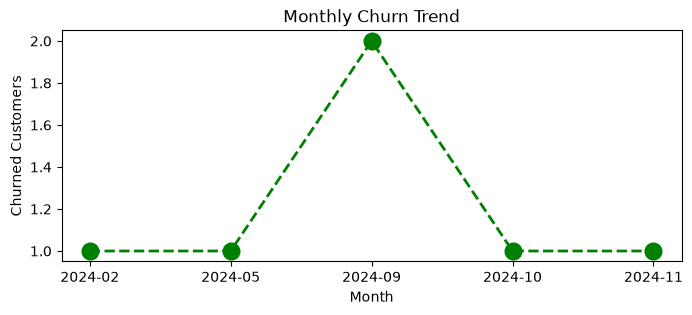

In [106]:
# ya data la plot kracha ahe 

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype('str'),churn_trend.values, color='green',marker='o',linestyle='dashed',
        linewidth=2,markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

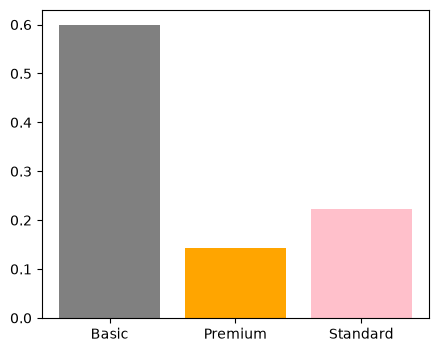

In [127]:
#4.2 churn by plan type

churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

colors = ['grey','orange','pink']
plt.figure(figsize=(5,4))

plt.bar(churn_plan.index, churn_plan.values,color=colors)
plt.show()

In [122]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'escalation', 'churn_risk', 'cancellation_month'],
      dtype='str')

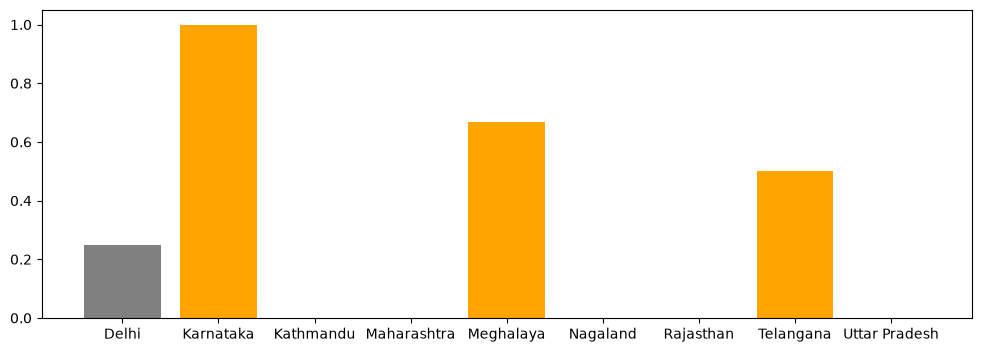

In [131]:
#4.3- churn by state

churn_plan = df_visual.groupby('state')['churn_flag'].mean()

#colors = ['grey','orange','pink']
plt.figure(figsize=(12,4))

plt.bar(churn_plan.index, churn_plan.values,color=colors)
plt.show()

In [132]:
# Visualization using Seaborn

In [134]:
# encoding - convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'escalation', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [155]:
#df_encoded = 
df_visual[['plan_type', 'contract_type','churn_score','churn_flag', 'churn_risk', 'escalation']].head()
   

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalation
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [156]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,0
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,0


In [144]:
import warnings
warnings.filterwarnings("ignore")

In [159]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type','churn_score','churn_flag', 'churn_risk', 'escalation']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes
    

<Axes: >

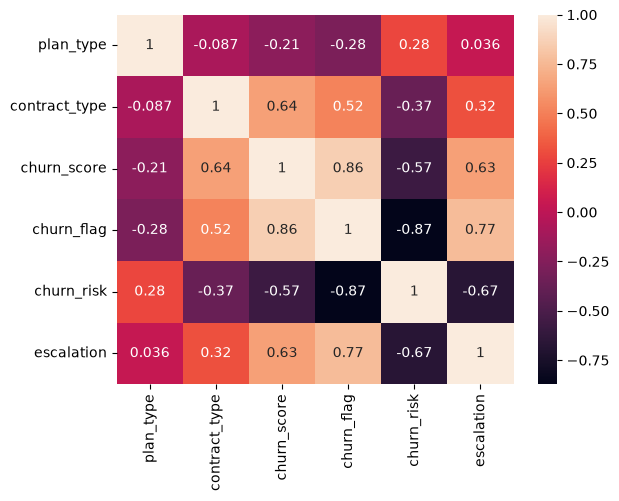

In [158]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [162]:
df_visual['churn_risk'].unique()

<StringArray>
['low', 'high', 'med']
Length: 3, dtype: str

In [166]:
# correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type','churn_score','churn_flag', 'churn_risk', 'escalation']]

order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type' :['Monthly', 'Annual'],
    'churn_risk' :['low', 'med', 'high']
}

for col,order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [167]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalation
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


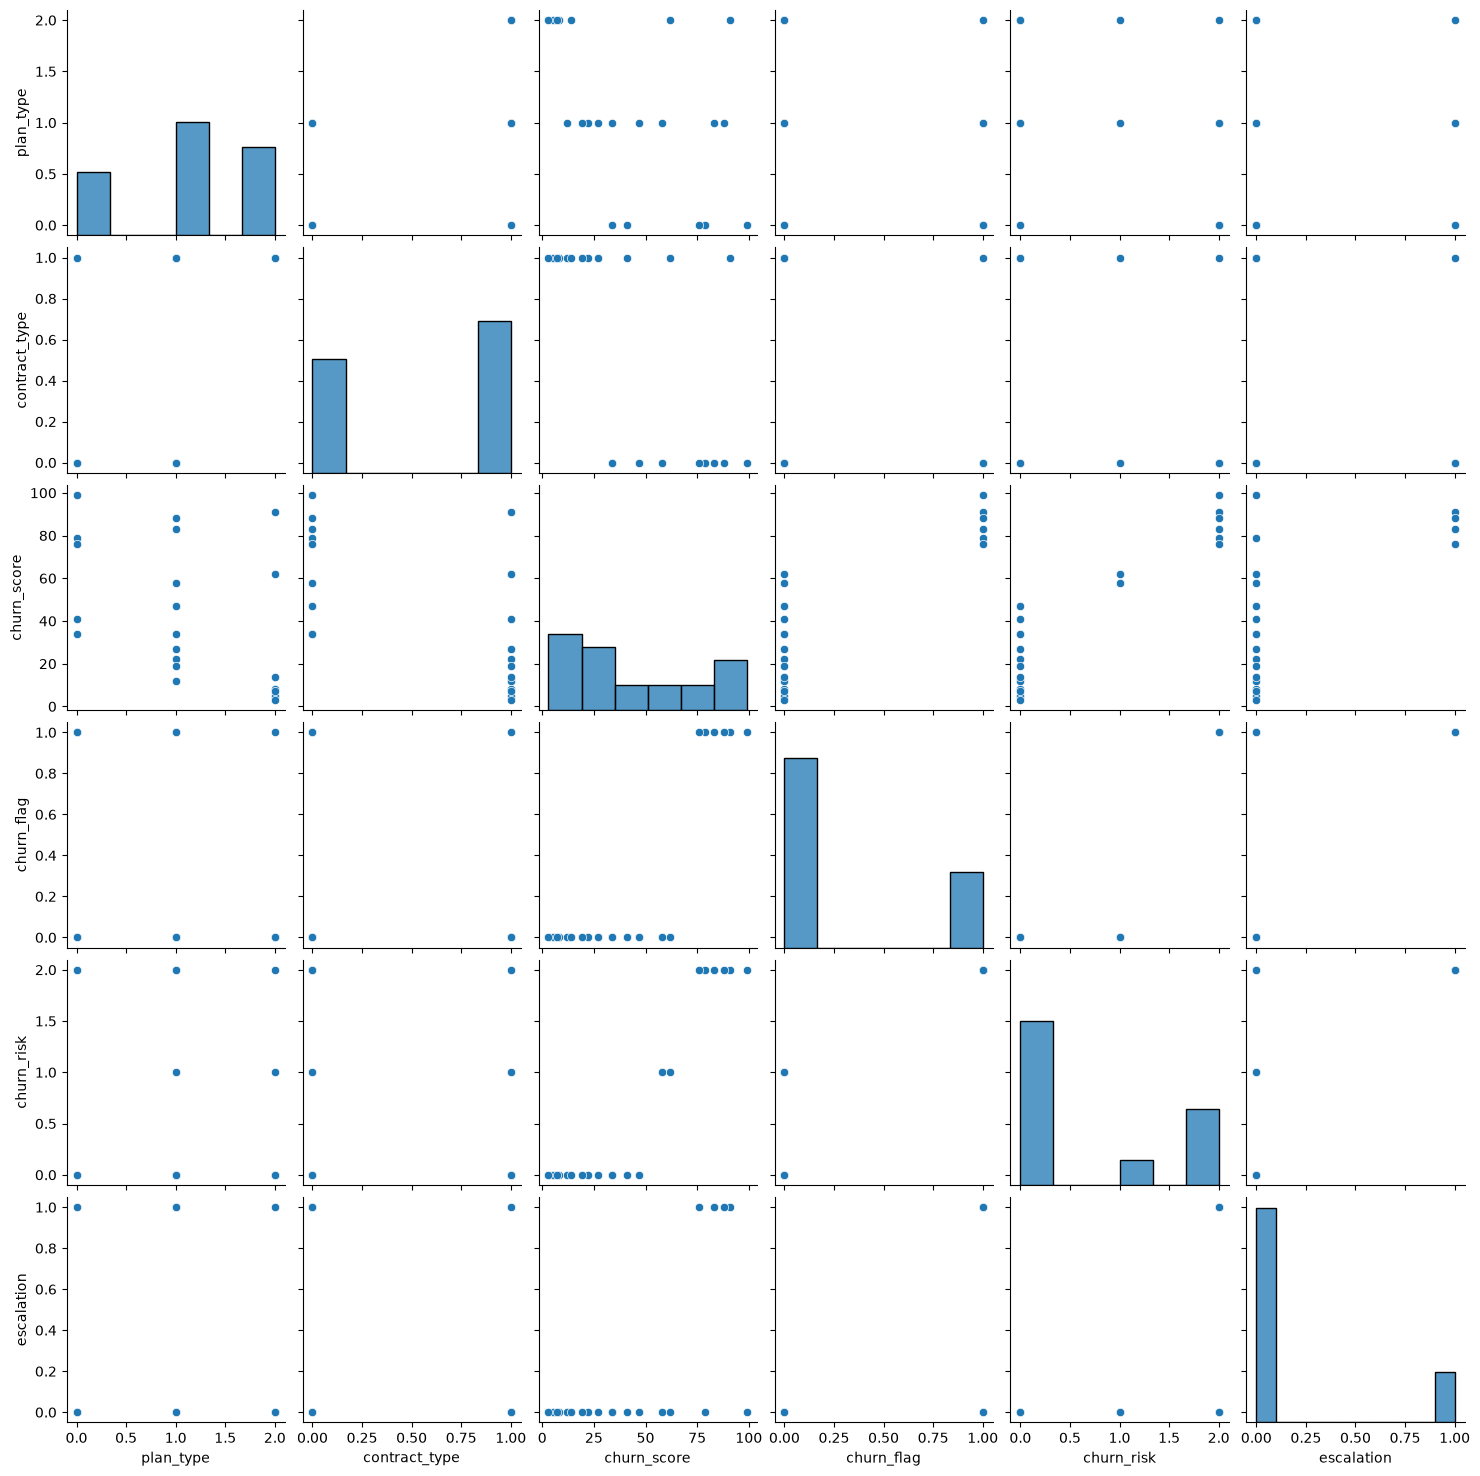

In [169]:
# pairplot - relationship in a dataset

sns.pairplot(df_encoded)

In [170]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'escalation', 'churn_risk', 'cancellation_month'],
      dtype='str')

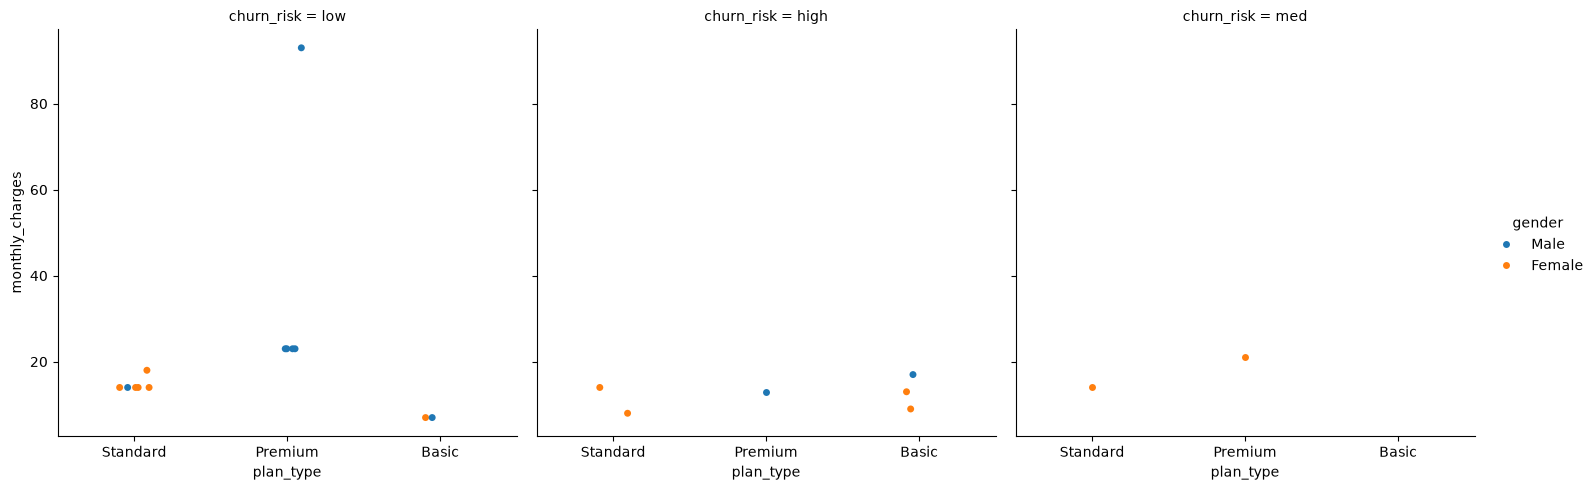

In [171]:
#Categorial/facegrid plot--multi-dimension comparison

sns.catplot(data=df_visual,
            x='plan_type',
            y='monthly_charges',
            hue='gender',
            col='churn_risk',)

In [172]:
# pivot table

In [177]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',   
    aggfunc='mean'
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [180]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'escalation', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [181]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc={
        'monthly_charges':'sum', 
        'customerid':'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [182]:
# working with sql in python(pandas)

In [185]:
# create database in sql

conn = sqlite3.connect('test_database.sqlite')

#table details
conn.execute("CREATE TABLE userss (first_name TEXT, country TEXT, budget INTEGER)")

#commit and save
conn.commit()

In [192]:
# insert data

cursor = conn.cursor()

#write sql query to insert records in sql table
cursor.execute(
    """
    INSERT INTO userss VALUES 
    ('madhura','India',5000),
    ('neha','London',25000),
    ('saloni','Germany',55000)

    
"""
)

# commit and save
conn.commit()

print("Data Inserted Successfully!")

Data Inserted Successfully!


In [193]:
# check inserted data in table

conn=sqlite3.connect('test_database.sqlite')
query = """ SELECT * FROM userss"""

df_results = pd.read_sql(query, conn)

df_results.head()

,first_name,country,budget
0,madhura,india,5000
1,neha,london,25000
2,saloni,germany,55000
3,madhura,India,5000
4,neha,London,25000


In [194]:
# aggregration 

query="""
      SELECT country, sum(budget) as total_budget
      FROM userss
      GROUP BY country
"""
df_agg = pd.read_sql(query, conn)
df_agg

,country,total_budget
0,Germany,55000
1,India,5000
2,London,25000
3,germany,55000
4,india,5000
5,london,25000


In [196]:
# always close the connection with db once the task is over
conn.close()